<a href="https://colab.research.google.com/github/Shahad-Hossain/nasa-image-enhancement/blob/main/Logarithmic_Operations_on_Colored_Images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from PIL import Image, ImageStat, ImageFilter
import math
from collections import defaultdict
import random
import matplotlib.pyplot as plt
import numpy as np
import cv2

In [ ]:
input1 = "cropped_soil.jpg"
try:
    img1 = Image.open(input1).convert('RGB') # Convert to RGB to ensure consistent 3-channel access
except FileNotFoundError:
    print(f"Error: The file '{input1}' was not found.")
    exit()

pixels1 = img1.load()

width1, height1 = img1.size

img1.save("greyscaled.jpg")
print(str(width1) + " " + str(height1))



input2 = "image_10.jpg"
try:
    img2 = Image.open(input2).convert('RGB') # Convert to RGB to ensure consistent 3-channel access
except FileNotFoundError:
    print(f"Error: The file '{input2}' was not found.")
    exit()

pixels2 = img2.load()

width2, height2 = img2.size

print(str(width2) + " " + str(height2))

170 170
800 583


In [ ]:
def circleKernel(radius):
  size = radius * 2 + 1
  kernel = []

  for y in range(size):
      row = []
      for x in range(size):
          dx = x - radius
          dy = y - radius

          if dx*dx + dy*dy <= radius*radius:
              row.append(1)
          else:
              row.append(0)

      kernel.append(row)

  return kernel

def subtract(img_1, img_2):
  width, height = img_1.size
  img_1Pixels = img_1.load()
  img_2Pixels = img_2.load()

  newImg = Image.new("L", size=(width, height))
  newPixels = newImg.load()
  for i in range(width):
    for j in range(height):
      newPixels[i, j] = img_1Pixels[i, j] - img_2Pixels[i, j]

  return newImg

def getMinNeighborCustom(imgPixels, width, height, x, y, neighborChecks):
  minNeighbor = 256

  boxWid = len(neighborChecks[0])
  boxHei = len(neighborChecks)

  widCount = max((boxWid//2) - x, 0)
  heiCount = 0
  for i in range(max(x - ((boxWid)//2), 0), min(width, x + ((boxWid + 1)//2))):
    heiCount = max((boxHei//2) - y, 0)
    for j in range(max(y - ((boxHei)//2), 0), min(height, y + ((boxHei + 1)//2))):
      if (neighborChecks[heiCount][widCount] == 1):
        minNeighbor = imgPixels[i, j] if imgPixels[i, j] < minNeighbor else minNeighbor
      heiCount += 1

    widCount += 1
  return minNeighbor

def getMaxNeighborCustom(imgPixels, width, height, x, y, neighborChecks):
  maxNeighbor = -1

  boxWid = len(neighborChecks[0])
  boxHei = len(neighborChecks)

  widCount = max((boxWid//2) - x, 0)
  heiCount = 0
  for i in range(max(x - ((boxWid)//2), 0), min(width, x + ((boxWid + 1)//2))):
    heiCount = max((boxHei//2) - y, 0)
    for j in range(max(y - ((boxHei)//2), 0), min(height, y + ((boxHei + 1)//2))):
      if (neighborChecks[heiCount][widCount] == 1):
        maxNeighbor = imgPixels[i, j] if imgPixels[i, j] > maxNeighbor else maxNeighbor
      heiCount += 1

    widCount += 1
  return maxNeighbor



def initializeVars(img):
  width, height = img.size

  pixels = img.load()

  return (pixels, width, height)


def greyscale(img):
  width, height = img.size
  pixels = img.load()

  outImg = Image.new("L", (width, height))
  outImgPixels = outImg.load()

  for i in range(width):
    for j in range(height):
      r, g, b = pixels[i, j]
      outImgPixels[i, j] = int(0.299 * r + 0.587 * g + 0.114 * b)

  return outImg










# Logarithmic Transformation
def inverse(img):
  imgPixels = img.load()
  width, height = img.size

  outImg = Image.new("RGB", (width, height))
  outImgPixels = outImg.load()

  for i in range(width):
    for j in range(height):
      r, g, b = imgPixels[i, j]

      outImgPixels[i, j] = (255 - r, 255 - g, 255 - b)

  return outImg


def logTransform(img):
  imgPixels = img.load()
  width, height = img.size
  constant = 255 / math.log(1 + max(img.getextrema()[0][1], img.getextrema()[1][1], img.getextrema()[2][1]))

  outImg = Image.new("RGB", (width, height))
  outImgPixels = outImg.load()
  for i in range(width):
    for j in range(height):
      r, g, b = imgPixels[i, j]

      newr = int(constant * math.log(1 + float(r)))
      newg = int(constant * math.log(1 + float(g)))
      newb = int(constant * math.log(1 + float(b)))

      outImgPixels[i, j] = (newr, newg, newb)

  return outImg

# Logarithmic Addition
def logAddition(img_1, img_2):
  loggedImg1 = (inverse(img_1))
  loggedImg1Pixels = loggedImg1.load()
  loggedImg2 = (inverse(img_2))
  loggedImg2Pixels = loggedImg2.load()

  width, height = loggedImg1.size

  outImg = Image.new("RGB", (width, height))
  outImgPixels = outImg.load()



  for i in range(width):
    for j in range(height):
      r1, g1, b1 = loggedImg1Pixels[i, j]
      r2, g2, b2 = loggedImg2Pixels[i, j]

      newr = int(r1 + r2 - ((r1 * r2) / 255))
      newg = int(g1 + g2 - ((g1 * g2) / 255))
      newb = int(b1 + b2 - ((b1 * b2) / 255))

      outImgPixels[i, j] = (newr, newg, newb)

  return inverse(outImg)

def logScalarMultiplication(img, scalar):
  imgPixels = img.load()

  width, height = img.size

  outImg = Image.new("RGB", (width, height))
  outImgPixels = outImg.load()

  for i in range(width):
    for j in range(height):
      r, g, b = imgPixels[i, j]

      newr = int(255 - 255 * math.pow(1 - (r / 255), scalar))
      newg = int(255 - 255 * math.pow(1 - (g / 255), scalar))
      newb = int(255 - 255 * math.pow(1 - (b / 255), scalar))

      outImgPixels[i, j] = (newr, newg, newb)

  return outImg



def greyLogScalarMultiplication(img, scalar):
  imgPixels = img.load()

  width, height = img.size

  outImg = Image.new("L", (width, height))
  outImgPixels = outImg.load()

  for i in range(width):
    for j in range(height):
      r = imgPixels[i, j]

      newr = int(255 - 255 * math.pow(1 - (r / 255), scalar))

      outImgPixels[i, j] = newr

  return outImg









def contrastStretch(img, alpha):
  scaler = 32
  pixels, width, height = initializeVars(img)
  outImg = Image.new("L", (width, height))
  outImgPixels = outImg.load()

  stats = ImageStat.Stat(img)
  mean = stats.mean

  def S_Curve_ContrastStretching(pixelValue):
    return int(255 / (1 + math.exp((-alpha * (pixelValue - mean[0])) / scaler)))

  for i in range(width):
    for j in range(height):
      pixelVal = pixels[i, j]

      outImgPixels[i, j] = S_Curve_ContrastStretching(pixelVal)

  return outImg

def contrastStretchLog(img, alpha):
  scaler = 32
  pixels, width, height = initializeVars(img)
  outImg = Image.new("L", (width, height))
  outImgPixels = outImg.load()

  stats = ImageStat.Stat(img)
  mean = stats.mean

  def S_Curve_ContrastStretching(pixelValue):
    return int(255 / (1 + math.exp(singleScalarMultiplication(singleLogarithmicSubtraction(pixelValue, mean[0]) / scaler, -alpha))))

  for i in range(width):
    for j in range(height):
      pixelVal = pixels[i, j]

      outImgPixels[i, j] = S_Curve_ContrastStretching(pixelVal)

  return outImg


def gammaCorrection(img, delta):
  pixels, width, height = initializeVars(img)
  outImg = Image.new("L", (width, height))
  outImgPixels = outImg.load()

  for i in range(width):
    for j in range(height):
       pixelVal = pixels[i, j]

       outImgPixels[i, j] = int(255 * math.pow((pixelVal / 255), (1 / delta)))

  return outImg

def marsEnhanceImage(img, alpha=2.5, scale=2):
  pixels, width, height = initializeVars(img)

  greyImg = greyLogAddition(contrastStretchLog(img.convert("L"), alpha), contrastStretch(img.convert("L"), alpha))

  greyImg = logMinMaxNormal(greyImg)

  #cv_img = np.array(greyImg)

  #result = cv2.bilateralFilter(cv_img, 5, 30, 30)

  #greyImg = Image.fromarray(result)

  hsv_img = img.convert("HSV")
  hsv_pixels = hsv_img.load()

  h, s, v = hsv_img.split()

  s = logMinMaxNormal(s)
  sPixels = s.load()
  #greyImg = greyImg.filter(ImageFilter.SMOOTH())
  greyPixels = greyImg.load()
  for i in range(width1):
    for j in range(height1):
      val = greyPixels[i, j]
      val2 = sPixels[i, j]
      hsv_pixels[i, j] = (hsv_pixels[i, j][0], val2, val)

  hsv_img = hsv_img.convert("RGB")

  outImg = logScalarMultiplication(logAddition(img, logScalarMultiplication(hsv_img, scale)), scale)

  return greyImg, outImg


def customErosion(img, neighborChecks):
  width, height = img.size

  newImg = Image.new("L", size=(width, height))
  pixels = img.load()
  newPixels = newImg.load()

  for i in range(width):
    if (i % 100 == 0):
      print("On Col " + str(i) + "/" + str(width))
    for j in range(height):
      minNeighbor = getMinNeighborCustom(pixels, width, height, i, j, neighborChecks)

      newPixels[i, j] = minNeighbor

  return newImg



def customDilation(img, neighborChecks):
  width, height = img.size

  newImg = Image.new("L", size=(width, height))
  pixels = img.load()
  newPixels = newImg.load()

  for i in range(width):
    if (i % 100 == 0):
      print("On Col " + str(i) + "/" + str(width))
    for j in range(height):
      maxNeighbor = getMaxNeighborCustom(pixels, width, height, i, j, neighborChecks)
      newPixels[i, j] = maxNeighbor

  return newImg

def binInvert(img):
  width, height = img.size
  newImg = Image.new("1", size=(width, height))
  pixels = img.load()
  newPixels = newImg.load()
  for i in range(width):
    for j in range(height):
      newPixels[i, j] = 1 - pixels[i, j]
  return newImg

def greyToBin(img, threshold):
  width, height = img.size

  newImg = Image.new("1", size=(width, height))
  pixels = img.load()
  newPixels = newImg.load()
  for i in range(width):
    for j in range(height):
      pixelVal = pixels[i, j]

      if (pixelVal >= threshold):
        newPixels[i, j] = 1
      else:
        newPixels[i, j] = 0

  return newImg







def showHistogramBar(img, midpoint=None, threshold=None):
    width, height = img.size
    pixels = img.load()

    # Build histogram
    hist = [0] * 256
    for i in range(width):
        for j in range(height):
            hist[pixels[i, j]] += 1

    # Plot as bar graph
    plt.figure(figsize=(10, 5))
    plt.bar(range(256), hist, width=1.0)

    # Optional markers
    if midpoint is not None:
        plt.axvline(midpoint, color='orange', linestyle='--', label=f"Midpoint ({midpoint})")

    if threshold is not None:
        plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold ({threshold})")

    plt.title("Grayscale Histogram (Bar Graph)")
    plt.xlabel("Pixel Intensity (0–255)")
    plt.ylabel("Frequency")
    plt.xlim([0, 255])

    if midpoint is not None or threshold is not None:
        plt.legend()

    plt.grid(True, axis='y')
    plt.show()

def getMeanVar(neighbors):

  mean = 0
  var = 0
  for val in neighbors:
    mean += val
    var += math.pow(val, 2)

  mean /= len(neighbors)
  var /= len(neighbors)
  var -= math.pow(mean, 2)

  return mean, var

def getNeighbors(imgPixels, width, height, x, y, size):
  neighbors = []
  for i in range(max(x - (size//2), 0), min(width, x + ((size - 1)//2))):
    for j in range(max(y - (size//2), 0), min(height, y + ((size - 1)//2))):
      neighbors.append(imgPixels[i, j])

  return neighbors


def varianceMask(img, threshold, boxSize):
  width, height = img.size
  pixels = img.load()

  newImg = Image.new("1", size=(width, height))
  newPixels = newImg.load()
  for i in range(width):
    for j in range(height):
      pixel = pixels[i, j]

      mean, var = getMeanVar(getNeighbors(pixels, width, height, i, j, boxSize))

      std = math.sqrt(var)

      if (std >= threshold):
        newPixels[i, j] = 1
      else:
        newPixels[i, j] = 0

  return newImg


def multiImageMasking(img_1, img_2, t1, t2):
  width, height = img_1.size

  pixels_1 = img_1.load()
  pixels_2 = img_2.load()

  newImg = Image.new("1", size=(width, height))
  newPixels = newImg.load()

  for i in range(width):
    for j in range(height):
      val1 = pixels_1[i, j]
      val2 = pixels_2[i, j]

      if (val1 >= t1 and val2 >= t2):
        newPixels[i, j] = 1
      else:
        newPixels[i, j] = 0


  return newImg


def singleLogarithmicSubtraction(a, b):
  M = 255

  return M * ((a - b) / (M - b))



def minMaxNormal(img):
  width, height = img.size
  pixels = img.load()

  newImg = Image.new("L", size=(width, height))
  newPixels = newImg.load()

  min_val, max_val = img.getextrema()
  for i in range(width):
    for j in range(height):
      pixelVal = pixels[i, j]

      newPixelVal = int(((pixelVal - min_val) / (max_val - min_val)) * 255)
      newPixels[i, j] = newPixelVal

  return newImg

def logMinMaxNormal(img):
  width, height = img.size
  pixels = img.load()

  newImg = Image.new("L", size=(width, height))
  newPixels = newImg.load()

  min_val, max_val = img.getextrema()
  for i in range(width):
    for j in range(height):
      pixelVal = pixels[i, j]

      newPixelVal = int(((singleLogarithmicSubtraction(pixelVal, min_val)) / (singleLogarithmicSubtraction(max_val, min_val))) * 255)
      newPixels[i, j] = newPixelVal

  return newImg


def greyLogAddition(img_1, img_2):
  width, height = img_1.size

  pixels_1 = img_1.load()
  pixels_2 = img_2.load()

  newImg = Image.new("L", size=(width, height))
  newPixels = newImg.load()

  for i in range(width):
    for j in range(height):
      a1 = pixels_1[i, j]
      b1 = pixels_2[i, j]

      newPixelVal = int(a1 + b1 - ((a1 * b1) / 255))
      newPixels[i, j] = newPixelVal

  return newImg

def singleScalarMultiplication(val, c):
  M = 255

  return M - M * math.pow((1 - (val / M)), c)

In [ ]:
newImg = contrastStretch(img1.convert("L"), 2.5)

newImg.save("test6.jpg")

In [ ]:
newImg = logAddition(img1, img2)

newImg.save("test4.jpg")

newImg2 = logScalarMultiplication(newImg, 20)

newImg2.save("test5.jpg")

In [ ]:
newImg = greyscale(img1)
newImg.save("output.jpg")

hsv_img = img1.convert("HSV")
hsv_pixels = hsv_img.load()

testImg = Image.open("test6.jpg").convert("L")
testPixels = testImg.load()
for i in range(width1):
  for j in range(height1):
    val = testPixels[i, j]

    hsv_pixels[i, j] = (hsv_pixels[i, j][0], hsv_pixels[i, j][1], val)

hsv_img = hsv_img.convert("RGB")

hsv_img.save("test2.jpg")

In [ ]:
img = cv2.imread("test6.jpg", 0)

result = cv2.bilateralFilter(img, 9, 50, 50)

cv2.imwrite("output.jpg", result)


True

In [ ]:
newImg2 = logScalarMultiplication(img2, 2)

newImg2.save("test5.jpg")

In [ ]:
newImg1, newImg2 = marsEnhanceImage(img1, 0.3, 1.4)

newImg1.save("test5.jpg")

newImg2.save("test6.jpg")

In [ ]:
neighborChecks = circleKernel(2)

newImg1 = subtract(customDilation(img1, neighborChecks), customErosion(img1, neighborChecks))

newImg1.save("filteredMorphGradient.jpg")

On Col 0/800
On Col 100/800
On Col 200/800
On Col 300/800
On Col 400/800
On Col 500/800
On Col 600/800
On Col 700/800
On Col 0/800
On Col 100/800
On Col 200/800
On Col 300/800
On Col 400/800
On Col 500/800
On Col 600/800
On Col 700/800


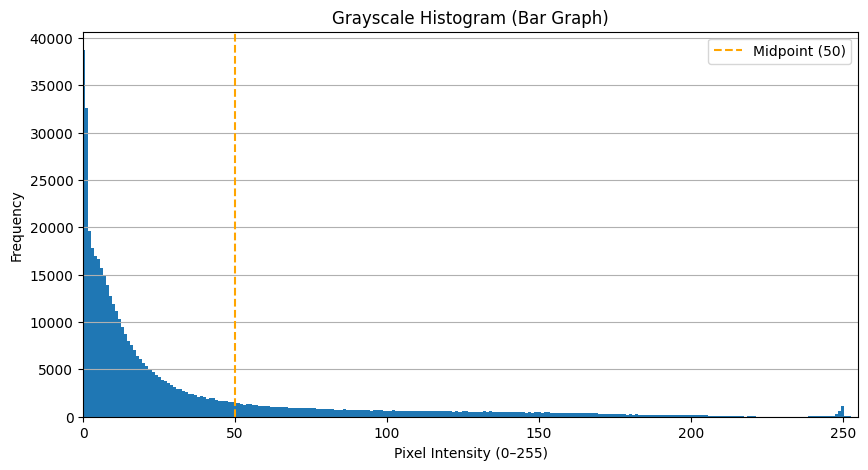

In [ ]:
midpoint = 50
showHistogramBar(img1, midpoint)
sosImg1 = greyToBin(img1, midpoint)
sosImg1.save("output2.jpg")

(array([1.96392e+05, 8.32890e+04, 6.67230e+04, 5.61210e+04, 4.97880e+04,
        4.37460e+04, 3.90450e+04, 3.63360e+04, 3.40380e+04, 3.08010e+04,
        2.88930e+04, 2.65230e+04, 2.42910e+04, 2.28390e+04, 2.26740e+04,
        2.17080e+04, 2.16150e+04, 2.06580e+04, 2.04690e+04, 1.99170e+04,
        1.97130e+04, 1.91940e+04, 1.93140e+04, 1.97610e+04, 1.90350e+04,
        1.85850e+04, 1.76520e+04, 1.82190e+04, 1.78290e+04, 1.71900e+04,
        1.60080e+04, 1.56810e+04, 1.53420e+04, 1.53210e+04, 1.46100e+04,
        1.38030e+04, 1.37190e+04, 1.33140e+04, 1.24200e+04, 1.24980e+04,
        1.21020e+04, 1.15290e+04, 1.10160e+04, 1.01760e+04, 9.61200e+03,
        9.16200e+03, 8.90400e+03, 8.30700e+03, 7.82400e+03, 7.09500e+03,
        6.70800e+03, 6.40200e+03, 5.89200e+03, 5.47500e+03, 4.84500e+03,
        4.44000e+03, 4.12200e+03, 4.29000e+03, 3.81900e+03, 3.76800e+03,
        4.01100e+03, 3.65700e+03, 5.07900e+03, 2.96700e+03, 2.50500e+03,
        2.40300e+03, 2.21100e+03, 2.06700e+03, 2.11

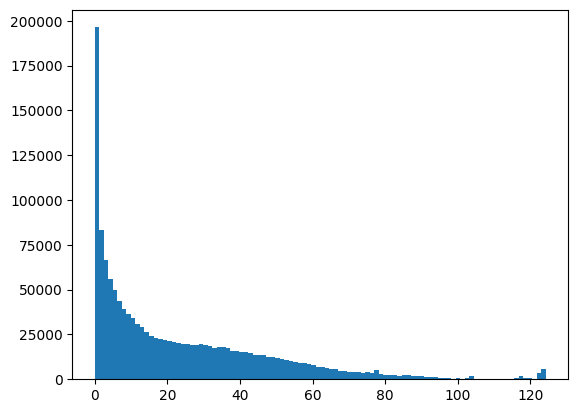

In [ ]:
def local_std(gray, ksize=9):
    gray = gray.astype(np.float32)

    mean = cv2.blur(gray, (ksize, ksize))
    mean_sq = cv2.blur(gray**2, (ksize, ksize))

    variance = mean_sq - mean**2
    std = np.sqrt(variance)
    return std




std_v = local_std(cv2.imread("filteredMorphGradient.jpg"))
plt.hist(std_v.ravel(), bins=100)

In [ ]:
sosImg10 = varianceMask(img1, 10, 9)

sosImg10.save("pls.jpg")

In [ ]:
sosImg = subtract(img1, greyLogScalarMultiplication(Image.open("fullyResult.jpg"), 1))

sosImg.save("sharpening.jpg")

In [ ]:
sosImg2 = multiImageMasking(img1, sosImg10, 10, 1)

sosImg2.save("fullyResult.jpg")

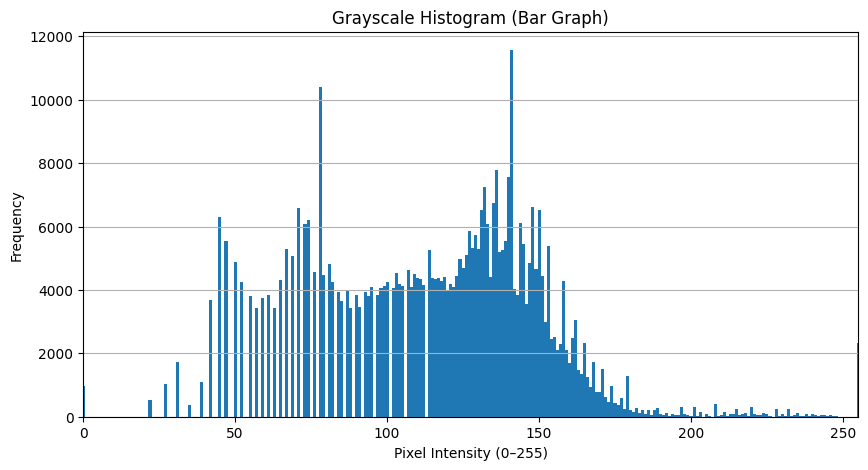

In [ ]:
img1HSV = img1.convert("HSV")
HSVPixels = img1HSV.load()
sImg = Image.new("L", (width1, height1))
sImgPixels = sImg.load()

for i in range(width1):
  for j in range(height1):
    sImgPixels[i, j] = HSVPixels[i, j][1]



sImg = gammaCorrection(sImg, 2)
sImgPixels = sImg.load()
showHistogramBar(sImg)

for i in range(width1):
  for j in range(height1):
    h, s, v = HSVPixels[i, j]
    newS = sImgPixels[i, j]
    HSVPixels[i, j] = (h, newS, v)


img1HSV.convert("RGB").save("stretchyStretchy.jpg")

In [ ]:
sosImg1, sosImg2 = marsEnhanceImage(img1)

sosImg1.save("algorithm1.jpg")
sosImg2.save("algorithm2.jpg")

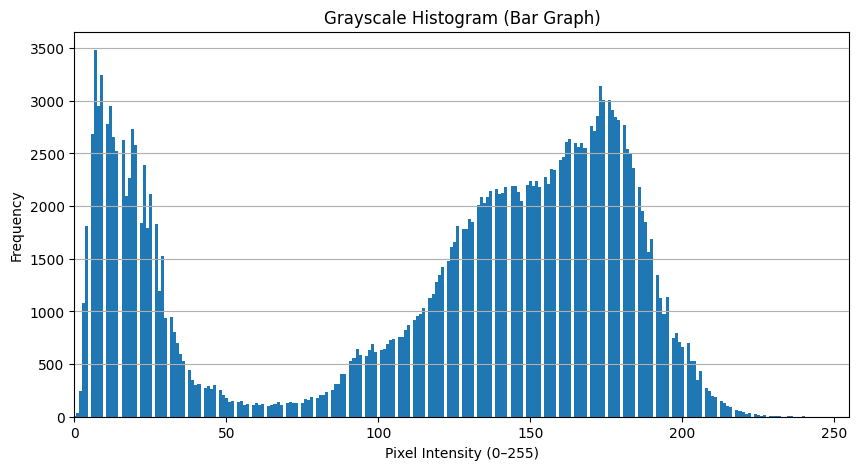

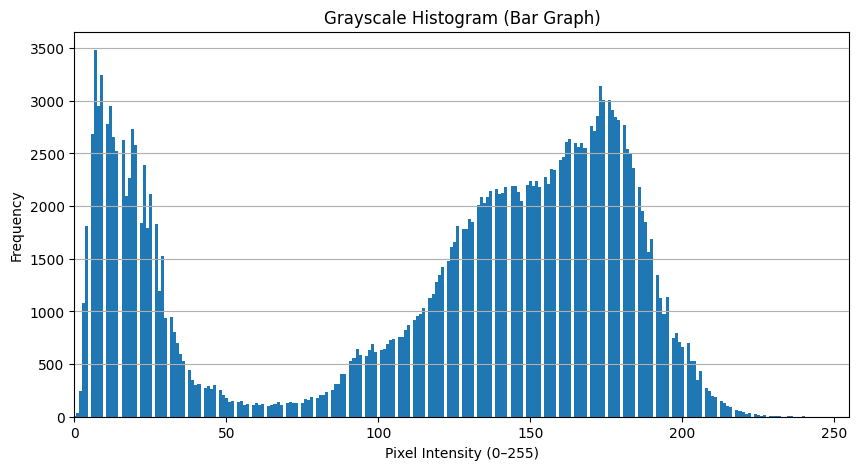

In [ ]:
sosImg1 = minMaxNormal(img1)
sosImg2 = logMinMaxNormal(img1)

showHistogramBar(sosImg1)
showHistogramBar(sosImg2)
sosImg1.save("normal.jpg")
sosImg2.save("logNormal.jpg")

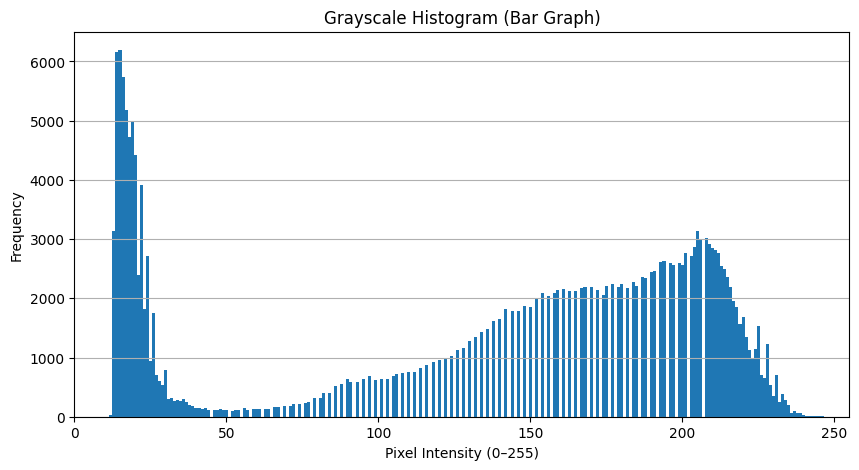

In [ ]:
sosImg = contrastStretch(img1, 2)

sosImg.save("stretch.jpg")

showHistogramBar(sosImg)

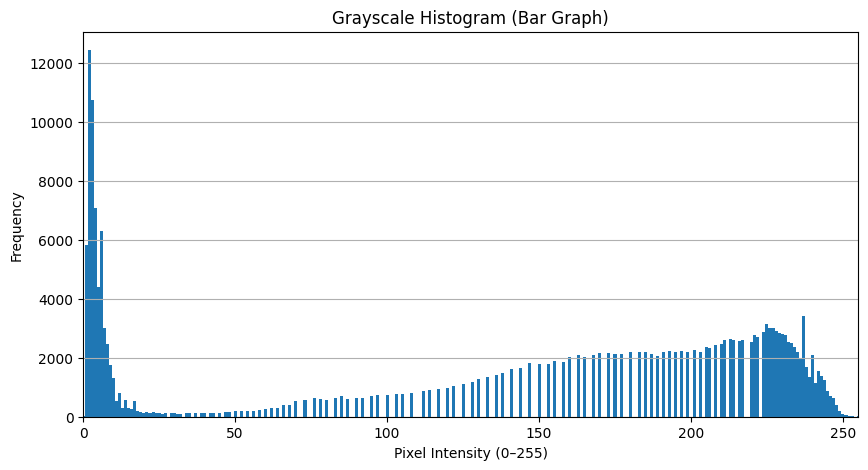

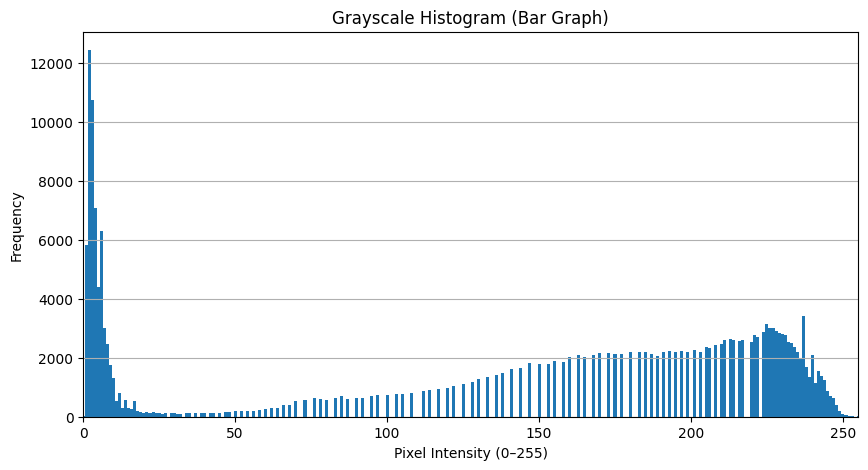

In [ ]:
sosImg1 = minMaxNormal(sosImg)
sosImg2 = logMinMaxNormal(sosImg)

sosImg1.save("newNormal.jpg")
sosImg2.save("newLogNormal.jpg")

showHistogramBar(sosImg1)
showHistogramBar(sosImg2)

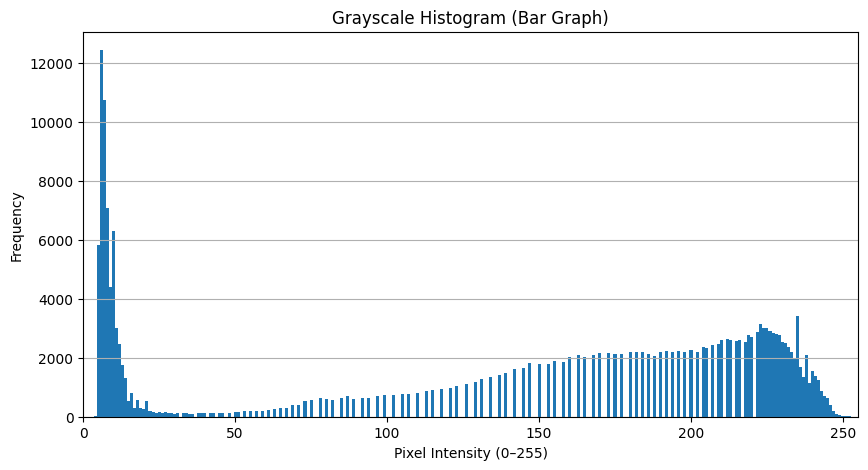

In [ ]:
sosImg = contrastStretchLog(img1.convert("L"), 0.7)

sosImg.save("test.jpg")

showHistogramBar(sosImg)

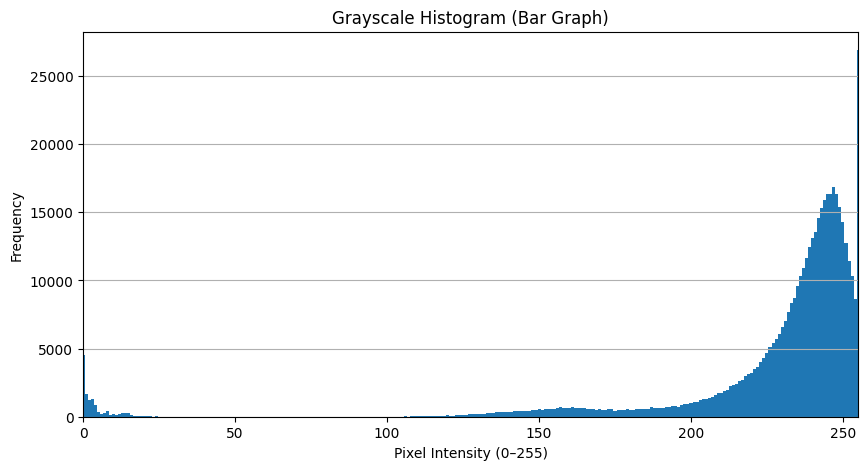

In [ ]:
sosImg = Image.open("test5.jpg")
showHistogramBar(sosImg)

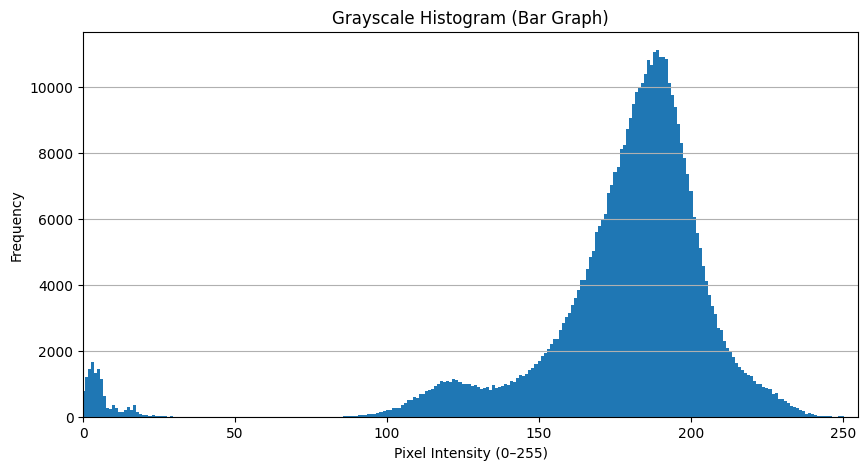

In [ ]:
sosImg = Image.open("greyscaled.jpg").convert("L")
showHistogramBar(sosImg)